# Detección de fraude en tarjetas de crédito

**Integrantes del grupo**

- Natalia San José Ortega
- Emilio Sánchez Martínez
- Josep Pérez Segura

Objetivo: construir un sistema de detección de fraude en tarjetas de crédito usando el dataset etiquetado de construcción.
La idea es intentar que el sistema tenga el mayor AUPR (Área bajo la curva Precision Recall) posible en producción:

from sklearn.metrics import average_precision_score

Se deberá entregar un csv con una única columna con tantas filas como tiene el fichero de producción, y con un score asociado de tal forma que las filas con mayor score sean las que tienen mayor probabilidad de ser fraude.

---

**Resumen de lo que hace este notebook**

1. Carga y comprueba los datos (celdas del notebook de partida, sin cambios de fondo).
2. Separa construcción en **desarrollo** (≈80 %) y **prueba** (≈20 %), sin que transacciones
   idénticas queden repartidas entre particiones. Prueba se evalúa **una sola vez** al final.
3. Compara en desarrollo, con validación cruzada agrupada de 4 iteraciones:
   - seis detectores de anomalías clásicos y kNN (aprenden solo de transacciones normales);
   - modelos supervisados (aprenden de normales y fraudes), con y sin el score de LOF como variable;
   - búsqueda de hiperparámetros y combinaciones de modelos.
4. Elige el modelo con el AUPR medio de validación cruzada, lo evalúa en prueba, lo reentrena
   con toda la construcción y genera el CSV de producción.
5. Comprueba la separación entre particiones y la integridad del fichero entregado, y cierra con una reflexión.

**Resultado (ejecución guardada).** Modelo final: **XGBoost con hiperparámetros ajustados**, entrenado
con toda la construcción. AUPR en validación cruzada de desarrollo: 0,856 ± 0,046. AUPR en prueba
(evaluación única): **0,824**. La referencia de detección de anomalías, LOF, obtiene 0,559 en validación cruzada y 0,622 en
prueba.
Entregable: `entregable_scores_produccion.csv`.

In [1]:
# Original: COLAB = True. Se detecta el entorno para que el notebook funcione
# igual en Google Colab (descarga los datos) y en local (usa los .zip de la carpeta).
import sys
COLAB = "google.colab" in sys.modules
print("Ejecutando en Colab:", COLAB)

Ejecutando en Colab: False


In [2]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.metrics import average_precision_score

import matplotlib.pyplot as plt
from IPython.display import clear_output

pd.options.display.max_columns = None

In [3]:
# Librerías añadidas por el grupo
import time
import warnings
from pathlib import Path

from IPython.display import display
from scipy.stats import rankdata
from sklearn.cluster import KMeans
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import ParameterSampler, StratifiedKFold, cross_val_predict
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBClassifier
except ImportError:  # Colab lo trae instalado; en local se instala si falta.
    %pip install -q xgboost
    from xgboost import XGBClassifier

SEMILLA = 42
pd.options.display.float_format = "{:,.4f}".format
plt.rcParams["figure.dpi"] = 110

# Carga del dataset

In [4]:
if COLAB:
    aux = "'https://drive.usercontent.google.com/download?id=1IyihCpU_krumRnPBvMR0ytEfzv_Z2Jg3&export=download&confirm=t&uuid=9699f0e2-e760-49fc-b12e-49f140095280'"
    print("wget {} -O ./credit_card_construction.csv.zip".format(aux))
    !wget $aux -O ./credit_card_construction.csv.zip
    !unzip -qq ./credit_card_construction.csv.zip

    aux = "'https://drive.usercontent.google.com/download?id=1N5xRbkchTR7FLskuIEmZPYHklsRVJy_q&export=download&confirm=t&uuid=9699f0e2-e760-49fc-b12e-49f140095280'"
    print("wget {} -O ./credit_card_production.csv.zip".format(aux))
    !wget $aux -O ./credit_card_production.csv.zip
    !unzip -qq ./credit_card_production.csv.zip

In [5]:
df_const = pd.read_csv("credit_card_construction.csv.zip", compression='zip', low_memory=False)
df_const

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
0,374.0000,-288.0000,-150.0000,-232.0000,-90.0000,262.0000,-262.0000,88.0000,-26.0000,152.0000,212.0000,60.0000,98.0000,-50.0000,134.0000,178.0000,64.0000,-322.0000,-58.0000,20.0000,144.0000,0
1,436.0000,-202.0000,-566.0000,-652.0000,166.0000,58.0000,-18.0000,-0.0000,54.0000,-54.0000,214.0000,214.0000,-2.0000,198.0000,248.0000,-688.0000,108.0000,100.0000,-34.0000,-136.0000,10.4600,0
2,388.0000,-128.0000,-56.0000,30.0000,-114.0000,104.0000,-210.0000,72.0000,298.0000,2.0000,28.0000,78.0000,-168.0000,22.0000,82.0000,172.0000,-218.0000,222.0000,36.0000,-40.0000,31.7200,0
3,-486.0000,4.0000,314.0000,-80.0000,-276.0000,-94.0000,-34.0000,94.0000,-252.0000,2.0000,-198.0000,-24.0000,116.0000,8.0000,138.0000,-110.0000,-86.0000,326.0000,-358.0000,-182.0000,134.8500,0
4,258.0000,-238.0000,300.0000,-70.0000,-374.0000,122.0000,-350.0000,92.0000,134.0000,94.0000,4.0000,-40.0000,-260.0000,-192.0000,-382.0000,182.0000,120.0000,-120.0000,282.0000,-6.0000,8.7000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170879,-398.0000,346.0000,-222.0000,-534.0000,322.0000,608.0000,-84.0000,288.0000,190.0000,204.0000,-50.0000,4.0000,-0.0000,-8.0000,152.0000,196.0000,-216.0000,2.0000,-116.0000,156.0000,22.2400,0
170880,-88.0000,212.0000,316.0000,-6.0000,8.0000,-180.0000,146.0000,-22.0000,-102.0000,-66.0000,-54.0000,76.0000,168.0000,-4.0000,152.0000,32.0000,-88.0000,-90.0000,2.0000,32.0000,3.8700,0
170881,166.0000,-530.0000,-632.0000,42.0000,-112.0000,-314.0000,322.0000,-186.0000,-264.0000,136.0000,-182.0000,16.0000,126.0000,152.0000,-70.0000,-444.0000,38.0000,136.0000,-182.0000,178.0000,"1,122.0600",0
170882,-304.0000,"-1,258.0000",-528.0000,266.0000,-334.0000,392.0000,272.0000,16.0000,150.0000,-140.0000,174.0000,130.0000,-52.0000,142.0000,258.0000,62.0000,-40.0000,-26.0000,-296.0000,660.0000,"2,657.2500",0


In [6]:
100*df_const["Class"].value_counts()/len(df_const)

Class
0   99.8274
1    0.1726
Name: count, dtype: float64

In [7]:
df_const.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
count,"170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000","170,884.0000"
mean,0.5895,-0.0509,0.2858,-0.0974,0.2840,0.0488,0.0054,0.2178,-0.0206,-0.0829,0.2855,0.2355,-0.2869,-0.1953,-0.0069,0.1966,-0.2889,-0.2781,0.3028,0.0802,132.1187,0.0017
std,390.9206,330.5020,302.0811,282.5722,270.7607,263.9279,241.1116,238.5902,219.3661,216.7876,204.4968,199.5914,198.8245,191.9950,183.0396,175.0586,169.9979,167.3256,162.1314,152.4714,363.4891,0.0415
min,"-11,282.0000","-14,544.0000","-6,594.0000","-1,136.0000","-6,418.0000","-5,232.0000","-8,302.0000","-14,644.0000","-2,686.0000","-4,880.0000",-868.0000,"-3,736.0000","-1,158.0000","-3,764.0000",-840.0000,"-2,826.0000","-5,032.0000","-1,900.0000","-1,442.0000","-4,730.0000",0.0000,0.0000
25%,-184.0000,-120.0000,-178.0000,-170.0000,-138.0000,-154.0000,-112.0000,-42.0000,-128.0000,-106.0000,-152.0000,-82.0000,-130.0000,-86.0000,-116.0000,-94.0000,-96.0000,-100.0000,-90.0000,-42.0000,8.5200,0.0000
50%,4.0000,14.0000,36.0000,-4.0000,-12.0000,-54.0000,8.0000,4.0000,-10.0000,-18.0000,-6.0000,28.0000,-4.0000,10.0000,10.0000,14.0000,-14.0000,0.0000,0.0000,-12.0000,33.0000,0.0000
75%,264.0000,162.0000,206.0000,150.0000,122.0000,80.0000,114.0000,66.0000,120.0000,92.0000,148.0000,124.0000,132.0000,98.0000,130.0000,104.0000,80.0000,100.0000,92.0000,26.0000,115.4450,0.0000
max,490.0000,"4,294.0000","1,876.0000","3,344.0000","6,960.0000","4,278.0000","6,860.0000","4,002.0000","3,118.0000","4,750.0000","2,334.0000","1,570.0000",874.0000,"2,106.0000","1,166.0000","1,412.0000","1,850.0000","1,008.0000","1,114.0000","7,884.0000","29,484.8000",1.0000


In [8]:
df_prod = pd.read_csv("./credit_card_production.csv.zip", compression='zip', low_memory=False)
df_prod

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
0,234.0000,48.0000,58.0000,106.0000,-30.0000,-56.0000,-22.0000,20.0000,-38.0000,-30.0000,360.0000,172.0000,-32.0000,-2.0000,136.0000,80.0000,8.0000,-44.0000,-52.0000,-24.0000,1.9400,NaN
1,408.0000,-126.0000,-426.0000,-312.0000,12.0000,-238.0000,56.0000,-48.0000,292.0000,-136.0000,154.0000,118.0000,-372.0000,204.0000,-48.0000,-214.0000,-4.0000,24.0000,270.0000,-44.0000,60.6800,NaN
2,-150.0000,84.0000,580.0000,-326.0000,-86.0000,-100.0000,74.0000,-32.0000,494.0000,-418.0000,228.0000,-348.0000,334.0000,184.0000,30.0000,-172.0000,142.0000,-28.0000,-144.0000,-18.0000,17.7700,NaN
3,296.0000,-134.0000,-388.0000,132.0000,-12.0000,-228.0000,114.0000,-70.0000,44.0000,-88.0000,304.0000,208.0000,82.0000,-112.0000,34.0000,78.0000,32.0000,192.0000,-54.0000,78.0000,416.3800,NaN
4,-594.0000,-214.0000,414.0000,308.0000,38.0000,196.0000,-46.0000,62.0000,70.0000,98.0000,270.0000,32.0000,-202.0000,-34.0000,236.0000,-86.0000,42.0000,28.0000,100.0000,-222.0000,138.0000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113918,392.0000,-98.0000,-42.0000,78.0000,-114.0000,42.0000,-202.0000,36.0000,490.0000,-38.0000,310.0000,-406.0000,134.0000,312.0000,-176.0000,100.0000,24.0000,160.0000,-42.0000,-54.0000,7.5400,NaN
113919,234.0000,16.0000,-48.0000,146.0000,36.0000,88.0000,-64.0000,56.0000,98.0000,-126.0000,136.0000,62.0000,-172.0000,-248.0000,-108.0000,56.0000,180.0000,88.0000,46.0000,-22.0000,18.4600,NaN
113920,-222.0000,106.0000,430.0000,-176.0000,74.0000,-58.0000,152.0000,-26.0000,34.0000,-118.0000,-66.0000,108.0000,110.0000,-142.0000,-78.0000,-88.0000,0.0000,-270.0000,-74.0000,18.0000,1.3400,NaN
113921,-82.0000,380.0000,-272.0000,182.0000,322.0000,-46.0000,238.0000,40.0000,-206.0000,-176.0000,-258.0000,18.0000,202.0000,-198.0000,-46.0000,-82.0000,232.0000,94.0000,162.0000,26.0000,23.6200,NaN


In [9]:
import plotly.express as px
import plotly.io as pio
if not COLAB:
    # Muestra el gráfico en Jupyter/VS Code sin incrustar la librería completa en el notebook.
    pio.renderers.default = "plotly_mimetype+notebook_connected"

In [10]:
df_const.var()

X1       152,818.9193
X2       109,231.5701
X3        91,252.9718
X4        79,847.0303
X5        73,311.3511
X6        69,657.9499
X7        58,134.8169
X8        56,925.2684
X9        48,121.4909
X10       46,996.8551
X11       41,818.9560
X12       39,836.7375
X13       39,531.1669
X14       36,862.0937
X15       33,503.4913
X16       30,645.4995
X17       28,899.2872
X18       27,997.8546
X19       26,286.5977
X20       23,247.5216
Amount   132,124.3374
Class          0.0017
dtype: float64

Las varianzas de `X1`…`X20` decrecen de forma ordenada, como ocurre con componentes principales
ordenadas por varianza explicada: las variables parecen estar ya transformadas y anonimizadas, así que
no les atribuimos significado económico. `Amount` no sigue ese patrón y tiene una escala propia.
El gráfico de dispersión del notebook de partida se ha movido a la exploración (sección 4) para
dibujarlo solo con datos de desarrollo.

# 1. Comprobación de los datos

Antes de modelar verificamos la estructura: 21 entradas (`X1`–`X20` y `Amount`) y `Class` como
respuesta (0 = normal, 1 = fraude). En producción `Class` está vacía deliberadamente: no se rellena
ni se usa. Guardamos una huella (hash) de las entradas de producción para comprobar al final que ni
su contenido ni su orden han cambiado.

In [11]:
columnas = [f"X{i}" for i in range(1, 21)] + ["Amount"]

for nombre, datos in [("construcción", df_const), ("producción", df_prod)]:
    assert list(datos.columns) == columnas + ["Class"], f"Columnas inesperadas en {nombre}"
    assert np.isfinite(datos[columnas].to_numpy()).all(), f"Hay ausentes o infinitos en {nombre}"
assert df_const["Class"].isin([0, 1]).all(), "Construcción debe tener etiquetas 0/1"
assert df_prod["Class"].isna().all(), "Las etiquetas de producción deberían estar vacías"
assert isinstance(df_prod.index, pd.RangeIndex)

X_prod = df_prod[columnas].copy()
N_PROD = len(X_prod)
HUELLA_PROD = pd.util.hash_pandas_object(X_prod, index=True).sum()

resumen = pd.DataFrame([
    {"Dataset": nombre, "Filas": len(datos), "Ausentes en entradas": int(datos[columnas].isna().sum().sum()),
     "Etiquetas ausentes": int(datos["Class"].isna().sum()),
     "Filas repetidas (copias tras la primera)": int(datos[columnas].duplicated().sum())}
    for nombre, datos in [("Construcción", df_const), ("Producción", df_prod)]
]).set_index("Dataset")
display(resumen)

# Transacciones de producción con entradas idénticas a alguna de construcción (solo informativo).
clave_const = pd.MultiIndex.from_frame(df_const[columnas])
clave_prod = pd.MultiIndex.from_frame(X_prod)
en_construccion = clave_prod.isin(clave_const)
print(f"Filas de producción idénticas a alguna de construcción: {en_construccion.sum():,} "
      f"({100 * en_construccion.mean():.2f} %)")

,Filas,Ausentes en entradas,Etiquetas ausentes,Filas repetidas (copias tras la primera)
Dataset,,,,
Construcción,170884,0,0,4167
Producción,113923,0,113923,2109


Filas de producción idénticas a alguna de construcción: 4,314 (3.79 %)


**Lectura.** No hay ausentes en las entradas y los ausentes de `Class` en producción son los esperados.
Hay transacciones repetidas (mismas 21 entradas) dentro de construcción y dentro de producción. No
eliminamos ninguna: en construcción mantendremos cada grupo de copias en una sola partición, para que
una copia no esté en entrenamiento y otra en validación (eso inflaría las métricas), y en producción hay
que puntuar todas las filas en su orden original.

Además, algunas filas de producción coinciden exactamente con filas de construcción. No es una fuga: es
información legítima que el modelo final podrá aprovechar, porque se entrena con toda la construcción.

# 2. Desbalance de clases

,Transacciones,Porcentaje
Normal (0),170589,99.8274
Fraude (1),295,0.1726


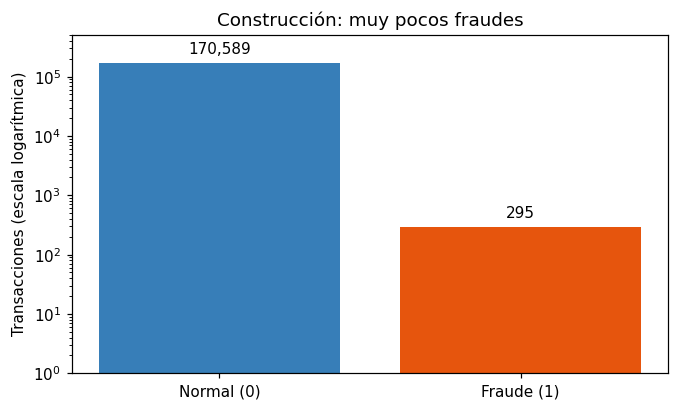

Predecir siempre 'normal' acertaría el 99.827 % de las filas sin detectar ningún fraude.
AUPR de un score aleatorio ≈ prevalencia = 0.00173


In [12]:
conteo = df_const["Class"].value_counts().reindex([0, 1])
tabla_clases = pd.DataFrame({"Transacciones": conteo, "Porcentaje": 100 * conteo / len(df_const)},
                            index=[0, 1]).rename(index={0: "Normal (0)", 1: "Fraude (1)"})
display(tabla_clases)

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(tabla_clases.index, tabla_clases["Transacciones"], color=["#377eb8", "#e6550d"])
ax.set_yscale("log")
ax.set_ylabel("Transacciones (escala logarítmica)")
ax.set_title("Construcción: muy pocos fraudes")
ax.bar_label(barras, labels=[f"{n:,}" for n in tabla_clases["Transacciones"]], padding=4)
ax.set_ylim(1, tabla_clases["Transacciones"].max() * 3)
plt.show()

PREVALENCIA = df_const["Class"].mean()
print(f"Predecir siempre 'normal' acertaría el {100 * (1 - PREVALENCIA):.3f} % de las filas sin detectar ningún fraude.")
print(f"AUPR de un score aleatorio ≈ prevalencia = {PREVALENCIA:.5f}")

**Lectura.** Solo el 0,17 % de las transacciones son fraude (la escala logarítmica hace visible la clase
minoritaria; las alturas no son proporcionales). La *accuracy* no sirve: decir siempre "normal" acierta
el 99,8 %.

Usamos la métrica del enunciado: el **AUPR** (área bajo la curva precisión-recall). Mide si los fraudes
quedan en las primeras posiciones de la ordenación, y su valor de referencia (un score aleatorio) es la
prevalencia, ≈ 0,0017. Lo calculamos con `average_precision_score`, como indica el notebook de partida.
scikit-learn llama a este valor *average precision*: suma las precisiones ponderadas por cada aumento de
recall, sin interpolar entre puntos de la curva. En la sección 9 lo comparamos con la integración
trapezoidal de la curva (`auc(recall, precision)`): en nuestros datos ambos cálculos coinciden
hasta la tercera decimal.

# 3. Separación: prueba reservada y validación cruzada agrupada

**Grupos.** Dos filas pertenecen al mismo grupo si sus 21 entradas son idénticas (sin mirar `Class`).
Comprobamos que no haya copias con etiquetas contradictorias y asignamos cada grupo entero a un fold.

**Cinco folds estratificados.** Repartimos por separado los grupos normales y los de fraude, así cada
fold tiene ≈20 % de las filas y ≈20 % de los fraudes. Usamos `np.random.RandomState`, cuya secuencia es
estable entre versiones: con `StratifiedGroupKFold` comprobamos que la misma semilla producía particiones
distintas según la versión de scikit-learn instalada.

| Parte | Folds | Uso |
|---|---|---|
| **Prueba** | 0 (≈20 %) | Se evalúa **una sola vez**, con el modelo ya elegido. |
| **Desarrollo** | 1–4 (≈80 %) | Validación cruzada: en cada iteración se entrena con 3 folds (≈60 %) y se valida con 1 (≈20 %). |
| **Producción** | — | Solo recibe scores al final; no interviene en ningún ajuste. |

Frente a una única partición de validación, la validación cruzada usa los ≈235 fraudes de desarrollo
para validar, y no solo ≈59, y permite ver cuánto varía el AUPR de una partición a otra.

*Nota:* las celdas anteriores (las del notebook de partida y el recuento de clases) se calculan sobre
toda la construcción, porque la separación aún no existía. Solo son descriptivas (recuentos,
varianzas, `describe`) y ninguna decisión de modelado depende de ellas. A partir de aquí todo se hace
con desarrollo.

In [13]:
def asignar_folds(datos, n_folds=5, semilla=SEMILLA):
    """Asigna cada grupo de transacciones idénticas a un fold, estratificando por clase."""
    grupo = pd.factorize(pd.MultiIndex.from_frame(datos[columnas]), sort=False)[0]
    clase_grupo = pd.Series(datos["Class"].to_numpy()).groupby(grupo).agg(["max", "nunique"])
    if (clase_grupo["nunique"] > 1).any():
        raise ValueError("Hay transacciones idénticas con etiquetas contradictorias.")
    rng = np.random.RandomState(semilla)
    fold_de_grupo = np.empty(len(clase_grupo), dtype=int)
    for clase in [0, 1]:
        ids = clase_grupo.index[clase_grupo["max"] == clase].to_numpy()
        ids = ids[rng.permutation(len(ids))]
        fold_de_grupo[ids] = np.arange(len(ids)) % n_folds
    return pd.DataFrame({"fila_original": np.arange(len(datos)), "grupo": grupo,
                         "fold": fold_de_grupo[grupo]})


asignacion = asignar_folds(df_const)
FOLD_PRUEBA, FOLDS_CV = 0, [1, 2, 3, 4]
es_prueba = asignacion["fold"].to_numpy() == FOLD_PRUEBA

# Desarrollo: lo único que se usa para explorar, comparar y ajustar.
X_dev = df_const.loc[~es_prueba, columnas].reset_index(drop=True)
y_dev = df_const.loc[~es_prueba, "Class"].astype(int).to_numpy()
fold_dev = asignacion.loc[~es_prueba, "fold"].to_numpy()
fila_dev = asignacion.loc[~es_prueba, "fila_original"].to_numpy()

# Prueba: queda apartada hasta la sección 9.
X_prueba = df_const.loc[es_prueba, columnas].reset_index(drop=True)
y_prueba = df_const.loc[es_prueba, "Class"].astype(int).to_numpy()
fila_prueba = asignacion.loc[es_prueba, "fila_original"].to_numpy()

# Comprobaciones de la separación
assert asignacion.groupby("grupo")["fold"].nunique().eq(1).all(), "Un grupo cruza folds"
assert set(fila_dev).isdisjoint(fila_prueba), "Desarrollo y prueba comparten filas"
assert len(fila_dev) + len(fila_prueba) == len(df_const), "Se han perdido filas"
grupos_dev = set(asignacion.loc[~es_prueba, "grupo"])
assert grupos_dev.isdisjoint(asignacion.loc[es_prueba, "grupo"]), "Desarrollo y prueba comparten grupos"

partes = pd.DataFrame({"fold": asignacion["fold"], "Class": df_const["Class"]})
tabla_folds = partes.groupby("fold")["Class"].agg(Filas="size", Fraudes="sum")
tabla_folds["% filas"] = 100 * tabla_folds["Filas"] / len(df_const)
tabla_folds["% fraude"] = 100 * tabla_folds["Fraudes"] / tabla_folds["Filas"]
tabla_folds.index = ["0 · prueba"] + [f"{k} · desarrollo" for k in FOLDS_CV]
display(tabla_folds)
print(f"Desarrollo: {len(X_dev):,} filas, {y_dev.sum()} fraudes · Prueba: {len(X_prueba):,} filas, {y_prueba.sum()} fraudes")
print("Ningún grupo de transacciones idénticas cruza folds; desarrollo y prueba son disjuntos.")

,Filas,Fraudes,% filas,% fraude
0 · prueba,34166,62,19.9937,0.1815
1 · desarrollo,34188,57,20.0066,0.1667
2 · desarrollo,34220,58,20.0253,0.1695
3 · desarrollo,34231,60,20.0317,0.1753
4 · desarrollo,34079,58,19.9428,0.1702


Desarrollo: 136,718 filas, 233 fraudes · Prueba: 34,166 filas, 62 fraudes
Ningún grupo de transacciones idénticas cruza folds; desarrollo y prueba son disjuntos.


# 4. Exploración de variables (solo desarrollo)

Exploramos únicamente desarrollo, para no tomar decisiones mirando prueba. Comparamos el importe y tres
variables elegidas de antemano (`X1`, `X2`, `X3`) entre normales y fraudes.

,count,mean,std,min,50%,90%,99%,max
Class,,,,,,,,
Normal,"136,485.0000",131.6357,356.8616,0.0000,33.0000,301.5000,"1,510.2368","17,847.1400"
Fraude,233.0000,187.3078,354.1844,0.0000,25.5900,522.9780,"1,721.4792","2,714.5200"


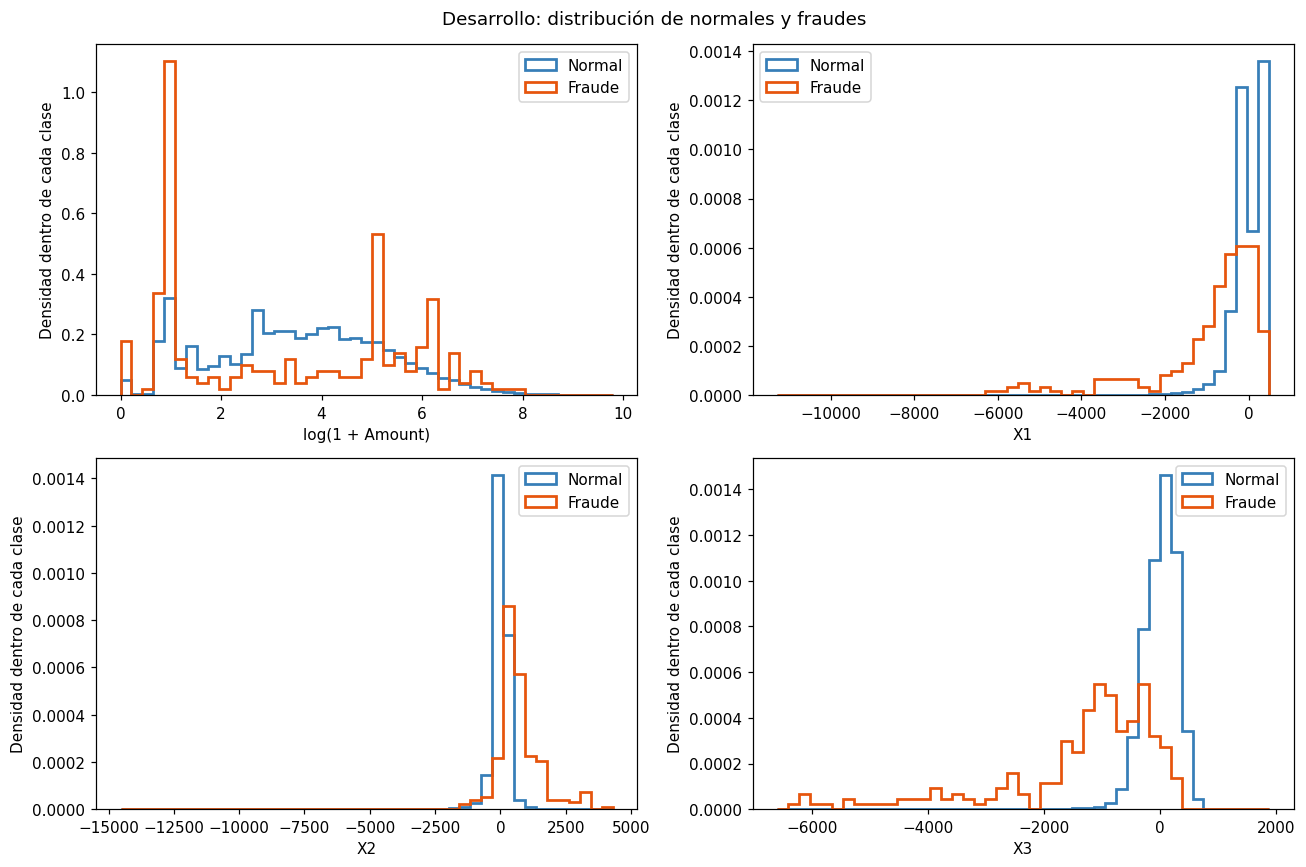

In [14]:
importes = pd.DataFrame({"Amount": X_dev["Amount"], "Class": y_dev}).groupby("Class")["Amount"]
display(importes.describe(percentiles=[0.5, 0.9, 0.99]).rename(index={0: "Normal", 1: "Fraude"}))

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(ejes.flat, ["Amount", "X1", "X2", "X3"]):
    valores = np.log1p(X_dev[col]) if col == "Amount" else X_dev[col]
    bins = np.histogram_bin_edges(valores, bins=45)
    for clase, nombre, color in [(0, "Normal", "#377eb8"), (1, "Fraude", "#e6550d")]:
        ax.hist(valores[y_dev == clase], bins=bins, density=True, histtype="step",
                linewidth=1.8, label=nombre, color=color)
    ax.set_xlabel("log(1 + Amount)" if col == "Amount" else col)
    ax.set_ylabel("Densidad dentro de cada clase")
    ax.legend()
fig.suptitle("Desarrollo: distribución de normales y fraudes")
fig.tight_layout()
plt.show()

In [15]:
# Gráfico del notebook de partida, aplicado solo a desarrollo: todos los fraudes y 5.000 normales.
muestra_grafico = pd.concat([
    X_dev[y_dev == 0].sample(5000, random_state=SEMILLA).assign(Class="Normal"),
    X_dev[y_dev == 1].assign(Class="Fraude"),
])
px.scatter(muestra_grafico, x="X1", y="X2", color="Class", hover_data=["Amount"], opacity=0.6)

**Lectura.** Cada histograma está normalizado dentro de su clase, así que compara formas, no cantidades.

- Los fraudes se desplazan hacia valores extremos: colas largas negativas en `X1` y, sobre todo, en `X3`,
  y valores positivos más altos en `X2`. `X3` es la que más separa de las cuatro, pero incluso en ella
  hay solapamiento.
- En el importe, los fraudes se concentran en cantidades muy pequeñas y en algunos valores concretos más
  altos. Su mediana es menor que la de las normales (25,6 frente a 33,0), pero sus percentiles 90 y 99
  son mayores (523 frente a 302 y 1.721 frente a 1.510).
- Ninguna variable separa sola las clases; por eso combinaremos las 21 con modelos multivariantes.

# 5. Protocolo de evaluación

Todos los modelos siguen la misma interfaz: `fit(X, y)` con los datos de entrenamiento de la iteración
y `score(X)` para devolver un número por fila, **mayor cuanto más sospechosa**. La función
`evaluar_cv`:

- recorre las 4 iteraciones de desarrollo (entrenar con 3 folds, validar con 1);
- crea y ajusta un modelo nuevo en cada iteración, de modo que escaladores y modelos solo ven el entrenamiento de esa iteración;
- calcula el AUPR, el ROC AUC y cuántos fraudes caen entre las 100 transacciones con mayor score (presupuesto de revisión ilustrativo; cada fold de validación tiene ≈58 fraudes);
- registra qué filas de construcción se han usado, para comprobar al final que prueba nunca ha entrado.

Resumimos con el AUPR medio y su desviación entre iteraciones: diferencias menores que esa desviación no
son concluyentes.

In [16]:
FILAS_USADAS_EN_DESARROLLO = set()   # filas originales que han entrado en algún ajuste o validación
RESULTADOS, CANDIDATOS = {}, {}


def iteraciones_cv():
    for k in FOLDS_CV:
        i_tr, i_va = np.flatnonzero(fold_dev != k), np.flatnonzero(fold_dev == k)
        FILAS_USADAS_EN_DESARROLLO.update(fila_dev[i_tr])
        FILAS_USADAS_EN_DESARROLLO.update(fila_dev[i_va])
        yield k, i_tr, i_va


def metricas(y, s, k_top=100):
    top = np.argsort(-s, kind="stable")[:k_top]   # empates: se respeta el orden original
    return {"AUPR": average_precision_score(y, s), "ROC AUC": roc_auc_score(y, s),
            "Fraudes top-100": int(y[top].sum()), "Fraudes en validación": int(y.sum())}


def evaluar_cv(nombre, crear):
    """Validación cruzada en desarrollo. `crear()` devuelve un modelo nuevo sin ajustar."""
    oof, filas = np.full(len(y_dev), np.nan), []
    for k, i_tr, i_va in iteraciones_cv():
        modelo = crear().fit(X_dev.iloc[i_tr], y_dev[i_tr])
        s = np.asarray(modelo.score(X_dev.iloc[i_va]), dtype=float)
        assert s.shape == (len(i_va),) and np.isfinite(s).all(), "Score no válido"
        oof[i_va] = s
        filas.append(metricas(y_dev[i_va], s))
    RESULTADOS[nombre] = {"folds": pd.DataFrame(filas, index=FOLDS_CV), "oof": oof}
    CANDIDATOS[nombre] = crear
    ap = RESULTADOS[nombre]["folds"]["AUPR"]
    print(f"{nombre:<34} AUPR = {ap.mean():.4f} ± {ap.std():.4f}   por fold: {np.round(ap.to_numpy(), 3)}")


def resumen_cv(nombres):
    filas = []
    for n in nombres:
        f = RESULTADOS[n]["folds"]
        filas.append({"Modelo": n, "AUPR medio": f["AUPR"].mean(), "AUPR desv.": f["AUPR"].std(),
                      "AUPR mín.": f["AUPR"].min(), "AUPR máx.": f["AUPR"].max(),
                      "ROC AUC media": f["ROC AUC"].mean(),
                      "Fraudes top-100 (media)": f["Fraudes top-100"].mean()})
    return pd.DataFrame(filas).set_index("Modelo").sort_values("AUPR medio", ascending=False)

# 6. Detectores de anomalías (aprenden solo la normalidad)

Primera aproximación, basada en el material de clase: cada detector aprende cómo son las transacciones
**normales** del entrenamiento y puntúa lo lejos que está cada transacción nueva de esa normalidad. Usamos
`Class` solo para quedarnos con las normales, así que es un enfoque de aprendizaje de la normalidad, no
totalmente no supervisado. Una anomalía estadística no tiene por qué ser fraude.

Por coste (sobre todo LOF, kNN y GMM) cada detector usa una muestra reproducible de hasta **20.000
normales** del entrenamiento de la iteración. Un `StandardScaler` ajustado a esa muestra evita que las
variables con más varianza dominen las distancias.

| Detector | Score (mayor = más anómalo) | Referencia de clase |
|---|---|---|
| Mahalanobis (`LedoitWolf`) | distancia al cuadrado al centro, teniendo en cuenta correlaciones | `AD_Distancias` |
| PCA (10 componentes) | error cuadrático de reconstrucción | `AD_reconstruccion` |
| Isolation Forest (200 árboles) | `-score_samples`: se aísla con pocos cortes | `AD_Tools_Sklearn` |
| GMM (4 gaussianas) | `-log densidad` | `AD_Probabilidad`, `AD_Tools_Sklearn` |
| LOF (20 vecinos, `novelty=True`) | densidad local menor que la de sus vecinos | `AD_Tools_Sklearn`, diapositivas |
| K-means (8 centroides) | distancia al centroide más cercano | diapositivas (VQ) |
| kNN (5 vecinos) | distancia media a las 5 normales más cercanas | diapositivas (distancias) |

Las configuraciones están fijadas de antemano, sin ajustarlas a validación. LOF se mantiene como
**referencia de detección de anomalías** durante todo el notebook.

In [17]:
def muestra_normales(y, max_normales=20_000, semilla=SEMILLA):
    """Posiciones de una muestra reproducible de normales, en orden creciente."""
    normales = np.flatnonzero(y == 0)
    n = min(max_normales, len(normales))
    return np.sort(np.random.RandomState(semilla).choice(normales, size=n, replace=False))


class Detector:
    """Detector de anomalías entrenado solo con normales de entrenamiento."""

    def __init__(self, metodo, max_normales=20_000):
        self.metodo, self.max_normales = metodo, max_normales

    def fit(self, X, y):
        self.posiciones = muestra_normales(y, self.max_normales)
        self.escalador = StandardScaler().fit(X.iloc[self.posiciones])
        Z = self.escalador.transform(X.iloc[self.posiciones])
        self.modelo = {
            "Mahalanobis": LedoitWolf(),
            "PCA": PCA(n_components=10, svd_solver="full"),
            "Isolation Forest": IsolationForest(n_estimators=200, max_samples=256,
                                                random_state=SEMILLA, n_jobs=-1),
            "GMM": GaussianMixture(n_components=4, covariance_type="full", reg_covar=1e-5,
                                   max_iter=200, random_state=SEMILLA),
            "LOF": LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1),
            "K-means": KMeans(n_clusters=8, n_init=10, random_state=SEMILLA),
            "kNN (k=5)": NearestNeighbors(n_neighbors=5),
        }[self.metodo].fit(Z)
        if self.metodo == "GMM":
            assert self.modelo.converged_, "GMM no ha convergido"
        return self

    def score(self, X):
        Z = self.escalador.transform(X)
        m = self.modelo
        if self.metodo == "Mahalanobis":
            return m.mahalanobis(Z)
        if self.metodo == "PCA":
            return np.mean((Z - m.inverse_transform(m.transform(Z))) ** 2, axis=1)
        if self.metodo == "K-means":
            return m.transform(Z).min(axis=1)
        if self.metodo == "kNN (k=5)":
            return m.kneighbors(Z)[0].mean(axis=1)
        return -m.score_samples(Z)   # IF, GMM y LOF: sklearn da valores menores a lo más anómalo


DETECTORES = ["Mahalanobis", "PCA", "Isolation Forest", "GMM", "LOF", "K-means", "kNN (k=5)"]
for metodo in DETECTORES:
    evaluar_cv(metodo, lambda metodo=metodo: Detector(metodo))
display(resumen_cv(DETECTORES))

Mahalanobis                        AUPR = 0.5567 ± 0.0539   por fold: [0.526 0.636 0.52  0.545]


PCA                                AUPR = 0.4038 ± 0.0804   por fold: [0.333 0.506 0.43  0.347]


Isolation Forest                   AUPR = 0.1862 ± 0.0455   por fold: [0.148 0.244 0.202 0.151]


GMM                                AUPR = 0.7251 ± 0.0345   por fold: [0.722 0.774 0.694 0.711]


LOF                                AUPR = 0.5590 ± 0.2000   por fold: [0.653 0.723 0.589 0.27 ]


K-means                            AUPR = 0.2858 ± 0.0493   por fold: [0.226 0.346 0.292 0.278]


kNN (k=5)                          AUPR = 0.4468 ± 0.0606   por fold: [0.424 0.535 0.396 0.433]


,AUPR medio,AUPR desv.,AUPR mín.,AUPR máx.,ROC AUC media,Fraudes top-100 (media)
Modelo,,,,,,
GMM,0.7251,0.0345,0.6936,0.7737,0.9440,46.7500
LOF,0.5590,0.2000,0.2704,0.7233,0.9621,46.2500
Mahalanobis,0.5567,0.0539,0.5200,0.6359,0.9699,42.5000
kNN (k=5),0.4468,0.0606,0.3963,0.5348,0.9726,43.5000
PCA,0.4038,0.0804,0.3326,0.5056,0.9573,33.0000
K-means,0.2858,0.0493,0.2262,0.3461,0.9660,26.2500
Isolation Forest,0.1862,0.0455,0.1485,0.2436,0.9652,21.2500


**Lectura.**

- **GMM es el mejor detector de anomalías** (AUPR 0,725 ± 0,035) y además el más estable: la mezcla de
  cuatro gaussianas describe varios patrones de normalidad.
- **LOF**, nuestra referencia, tiene un AUPR medio de 0,559, pero es **muy inestable**: va de 0,27 a 0,72
  según la iteración. Su resultado depende mucho de qué normales y qué fraudes caen en cada partición. Una
  sola partición de validación habría dado una imagen engañosa de él, en uno u otro sentido.
- Mahalanobis (0,557) queda al nivel de LOF; kNN (0,447), PCA (0,404), K-means (0,286) e Isolation Forest
  (0,186) quedan por detrás.
- Todos superan con creces el azar (0,0017) y tienen ROC AUC > 0,94. Isolation Forest tiene un ROC AUC
  de 0,965 con el peor AUPR: con este desbalance, el ROC AUC apenas distingue entre métodos. Lo que importa
  es la precisión en las primeras posiciones, que es lo que mide el AUPR.

# 7. Modelos supervisados (aprenden de normales y fraudes)

El enunciado pide un sistema construido **con el dataset etiquetado** y con el mayor AUPR posible en
producción. Los detectores anteriores desperdician la información de los ≈235 fraudes etiquetados de
desarrollo. La comparativa ADBench vista en clase (diapositiva 54) muestra que, en cuanto se dispone de
anomalías etiquetadas, los métodos supervisados (RF, XGBoost, LightGBM, CatBoost…) superan al mejor
método no supervisado. Aquí tenemos etiquetados todos los fraudes de construcción.

Candidatos iniciales, con configuraciones razonables fijadas antes de mirar resultados:

- **Regresión logística** (con escalado): referencia lineal.
- **kNN supervisado (cociente de distancias)**: distancia media a las 5 normales más cercanas dividida
  por la distancia media a los 5 fraudes más cercanos; es alto si la transacción está cerca de fraudes
  conocidos y lejos de normales. *Nota:* la conocida cota de Cover y Hart (el error del 1-NN es como mucho
  el doble del error de Bayes con infinitos datos) se refiere a la tasa de error de clasificación, no al
  AUPR, así que no garantiza nada sobre esta métrica.
- **Random Forest**, **HistGradientBoosting** y **XGBoost**: conjuntos de árboles, robustos a escalas y
  colas largas, sin necesidad de transformar variables.

No sobremuestreamos ni equilibramos: los árboles manejan el desbalance y el AUPR solo depende del orden de
los scores. Si se usara sobremuestreo, debería hacerse solo dentro del entrenamiento de cada iteración.

In [18]:
class Supervisado:
    """Clasificador entrenado con normales y fraudes; opcionalmente añade el score LOF como variable."""

    def __init__(self, fabrica, usar_lof=False):
        self.fabrica, self.usar_lof = fabrica, usar_lof

    def _con_lof(self, X, entrenamiento=False):
        s = self.lof.score(X)
        if entrenamiento:
            # Las normales con las que se ajustó LOF reciben su LOF calculado sin contarse a sí mismas.
            s[self.lof.posiciones] = -self.lof.modelo.negative_outlier_factor_
        return X.assign(LOF=s)

    def fit(self, X, y):
        if self.usar_lof:
            self.lof = Detector("LOF").fit(X, y)       # solo normales de este entrenamiento
            X = self._con_lof(X, entrenamiento=True)
        self.modelo = self.fabrica().fit(X, y)
        return self

    def score(self, X):
        if self.usar_lof:
            X = self._con_lof(X)
        return self.modelo.predict_proba(X)[:, 1]


class KNNCociente:
    """kNN supervisado: d(normales más cercanas) / d(fraudes más cercanos)."""

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.escalador = StandardScaler().fit(X)
        Z = self.escalador.transform(X)
        self.nn_normal = NearestNeighbors(n_neighbors=self.k).fit(Z[y == 0])
        self.nn_fraude = NearestNeighbors(n_neighbors=self.k).fit(Z[y == 1])
        return self

    def score(self, X):
        Z = self.escalador.transform(X)
        d_normal = self.nn_normal.kneighbors(Z)[0].mean(axis=1)
        d_fraude = self.nn_fraude.kneighbors(Z)[0].mean(axis=1)
        return d_normal / np.maximum(d_fraude, 1e-12)


def fabrica_rf(**p):
    return lambda: RandomForestClassifier(**{"n_estimators": 300, "min_samples_leaf": 2, **p},
                                          n_jobs=-1, random_state=SEMILLA)

def fabrica_hgb(**p):
    base = {"learning_rate": 0.05, "max_iter": 300, "max_leaf_nodes": 15, "l2_regularization": 1.0}
    return lambda: HistGradientBoostingClassifier(**{**base, **p}, random_state=SEMILLA)

def fabrica_xgb(**p):
    base = {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 4, "subsample": 0.8,
            "colsample_bytree": 0.8}
    return lambda: XGBClassifier(**{**base, **p}, n_jobs=-1, random_state=SEMILLA, eval_metric="aucpr")


evaluar_cv("Regresión logística", lambda: Supervisado(
    lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))))
evaluar_cv("kNN cociente (k=5)", lambda: KNNCociente(k=5))
evaluar_cv("Random Forest", lambda: Supervisado(fabrica_rf()))
evaluar_cv("HistGradientBoosting", lambda: Supervisado(fabrica_hgb()))
evaluar_cv("XGBoost", lambda: Supervisado(fabrica_xgb()))
SUPERVISADOS = ["Regresión logística", "kNN cociente (k=5)", "Random Forest", "HistGradientBoosting", "XGBoost"]
display(resumen_cv(SUPERVISADOS + ["GMM", "LOF"]))

Regresión logística                AUPR = 0.7594 ± 0.0251   por fold: [0.756 0.748 0.795 0.738]


kNN cociente (k=5)                 AUPR = 0.8055 ± 0.0740   por fold: [0.904 0.801 0.793 0.725]


Random Forest                      AUPR = 0.8341 ± 0.0516   por fold: [0.906 0.8   0.838 0.793]


HistGradientBoosting               AUPR = 0.8388 ± 0.0237   por fold: [0.873 0.822 0.838 0.823]


XGBoost                            AUPR = 0.8553 ± 0.0431   por fold: [0.908 0.815 0.872 0.826]


,AUPR medio,AUPR desv.,AUPR mín.,AUPR máx.,ROC AUC media,Fraudes top-100 (media)
Modelo,,,,,,
XGBoost,0.8553,0.0431,0.8147,0.9083,0.9765,51.2500
HistGradientBoosting,0.8388,0.0237,0.8217,0.8726,0.9718,51.0000
Random Forest,0.8341,0.0516,0.7931,0.9057,0.9644,50.5000
kNN cociente (k=5),0.8055,0.0740,0.7246,0.9040,0.9791,49.5000
Regresión logística,0.7594,0.0251,0.7381,0.7954,0.9828,50.0000
GMM,0.7251,0.0345,0.6936,0.7737,0.9440,46.7500
LOF,0.5590,0.2000,0.2704,0.7233,0.9621,46.2500


**Lectura.**

- **Todos los modelos supervisados superan al mejor detector de anomalías** (GMM, 0,725). Es lo que
  anticipaba ADBench: con etiquetas, aprender directamente qué distingue un fraude es mejor que modelar
  solo la normalidad.
- XGBoost (0,855), HistGradientBoosting (0,839) y Random Forest (0,834) quedan muy juntos. Sus
  diferencias son menores que la desviación entre iteraciones (0,02–0,05), así que todavía no hay un
  ganador claro.
- El kNN supervisado (0,806) se acerca a los árboles, pero es el más variable (de 0,72 a 0,90).
- La regresión logística, lineal, se queda en 0,759 aunque tiene el **mayor ROC AUC** (0,983): otra vez,
  el ROC AUC y el AUPR no ordenan igual los modelos.

## 7.1. LOF como variable de entrada

En vez de mezclar scores, probamos a dar al modelo supervisado el score de LOF como **variable 22**. Para
no introducir fugas, en cada iteración LOF se ajusta solo con normales del entrenamiento de esa iteración.
Las normales que forman parte de ese ajuste reciben su LOF calculado sin contarse a sí mismas
(`negative_outlier_factor_`); el resto de filas, y las de validación, se puntúan como datos nuevos.

In [19]:
evaluar_cv("HistGradientBoosting + LOF", lambda: Supervisado(fabrica_hgb(), usar_lof=True))
evaluar_cv("XGBoost + LOF", lambda: Supervisado(fabrica_xgb(), usar_lof=True))
display(resumen_cv(["HistGradientBoosting", "HistGradientBoosting + LOF", "XGBoost", "XGBoost + LOF"]))

HistGradientBoosting + LOF         AUPR = 0.8430 ± 0.0483   por fold: [0.907 0.794 0.848 0.823]


XGBoost + LOF                      AUPR = 0.8541 ± 0.0425   por fold: [0.909 0.815 0.867 0.826]


,AUPR medio,AUPR desv.,AUPR mín.,AUPR máx.,ROC AUC media,Fraudes top-100 (media)
Modelo,,,,,,
XGBoost,0.8553,0.0431,0.8147,0.9083,0.9765,51.2500
XGBoost + LOF,0.8541,0.0425,0.8151,0.9085,0.9784,51.5000
HistGradientBoosting + LOF,0.8430,0.0483,0.7937,0.9074,0.9751,50.7500
HistGradientBoosting,0.8388,0.0237,0.8217,0.8726,0.9718,51.0000


**Lectura.** Añadir LOF como variable cambia el AUPR en menos de 0,005 (HistGradientBoosting 0,839 →
0,843; XGBoost 0,855 → 0,854), muy por debajo del ruido entre iteraciones. Los árboles ya extraen de
las 21 variables la información que aporta LOF. Por simplicidad, no lo incluimos en el modelo final, y
LOF queda como referencia de detección de anomalías.

## 7.2. Búsqueda de hiperparámetros

Ajustamos los dos mejores modelos de árboles con una **búsqueda aleatoria de 20 configuraciones** cada
uno, evaluadas con la misma validación cruzada de desarrollo. Prueba no interviene.

Elegir la mejor de 20 configuraciones con la misma validación cruzada introduce un sesgo optimista: el
AUPR de la ganadora tiende a sobrestimar su rendimiento real. Por eso la evaluación en prueba (sección 9)
es la estimación honesta.

`BUSCAR_HIPERPARAMETROS = False` salta la búsqueda (varios minutos en Colab) y usa las configuraciones
que ganaron en nuestra ejecución.

In [20]:
BUSCAR_HIPERPARAMETROS = True
N_CONFIGURACIONES = 20

ESPACIO_HGB = {"learning_rate": [0.02, 0.05, 0.1], "max_iter": [200, 400, 800],
               "max_leaf_nodes": [7, 15, 31], "min_samples_leaf": [10, 20, 50],
               "l2_regularization": [0.0, 1.0, 5.0], "max_features": [0.5, 0.8, 1.0]}
ESPACIO_XGB = {"n_estimators": [200, 400, 800], "learning_rate": [0.02, 0.05, 0.1],
               "max_depth": [3, 4, 6], "subsample": [0.7, 0.85, 1.0],
               "colsample_bytree": [0.5, 0.8, 1.0], "min_child_weight": [1, 3, 10],
               "reg_lambda": [1.0, 5.0], "scale_pos_weight": [1, 5]}
# Ganadoras en nuestra ejecución (se usan si no se repite la búsqueda).
MEJOR_HGB_GUARDADO = {"min_samples_leaf": 50, "max_leaf_nodes": 7, "max_iter": 800,
                      "max_features": 0.5, "learning_rate": 0.05, "l2_regularization": 5.0}
MEJOR_XGB_GUARDADO = {"subsample": 0.7, "scale_pos_weight": 5, "reg_lambda": 1.0, "n_estimators": 400,
                      "min_child_weight": 1, "max_depth": 4, "learning_rate": 0.05, "colsample_bytree": 1.0}


def buscar(nombre, fabrica, espacio):
    configuraciones = list(ParameterSampler(espacio, n_iter=N_CONFIGURACIONES, random_state=SEMILLA))
    filas, inicio = [], time.time()
    for i, params in enumerate(configuraciones):
        aps = []
        for k, i_tr, i_va in iteraciones_cv():
            m = fabrica(**params)().fit(X_dev.iloc[i_tr], y_dev[i_tr])
            aps.append(average_precision_score(y_dev[i_va], m.predict_proba(X_dev.iloc[i_va])[:, 1]))
        filas.append({"config": i, **params, "AUPR medio": np.mean(aps), "AUPR desv.": np.std(aps, ddof=1)})
    tabla = pd.DataFrame(filas).sort_values("AUPR medio", ascending=False).set_index("config")
    print(f"{nombre}: {len(configuraciones)} configuraciones evaluadas en {time.time() - inicio:.0f} s")
    return tabla, configuraciones[tabla.index[0]]


if BUSCAR_HIPERPARAMETROS:
    tabla_hgb, MEJOR_HGB = buscar("HistGradientBoosting", fabrica_hgb, ESPACIO_HGB)
    display(tabla_hgb.head(5))
    tabla_xgb, MEJOR_XGB = buscar("XGBoost", fabrica_xgb, ESPACIO_XGB)
    display(tabla_xgb.head(5))
else:
    MEJOR_HGB, MEJOR_XGB = MEJOR_HGB_GUARDADO, MEJOR_XGB_GUARDADO
print("HGB elegido:", MEJOR_HGB)
print("XGB elegido:", MEJOR_XGB)

evaluar_cv("HistGradientBoosting ajustado", lambda: Supervisado(fabrica_hgb(**MEJOR_HGB)))
evaluar_cv("XGBoost ajustado", lambda: Supervisado(fabrica_xgb(**MEJOR_XGB)))

HistGradientBoosting: 20 configuraciones evaluadas en 64 s


,min_samples_leaf,max_leaf_nodes,max_iter,max_features,learning_rate,l2_regularization,AUPR medio,AUPR desv.
config,,,,,,,,
18,50,7,800,0.5000,0.0500,5.0000,0.8445,0.0361
2,50,15,200,1.0000,0.0200,1.0000,0.8411,0.0321
11,20,31,200,1.0000,0.1000,5.0000,0.8405,0.0433
5,50,15,800,0.5000,0.0200,1.0000,0.8385,0.0405
10,50,7,800,0.5000,0.0500,1.0000,0.8384,0.0245


XGBoost: 20 configuraciones evaluadas en 129 s


,subsample,scale_pos_weight,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,AUPR medio,AUPR desv.
config,,,,,,,,,,
14,0.7000,5,1.0000,400,1,4,0.0500,1.0000,0.8557,0.0464
7,1.0000,1,1.0000,400,3,6,0.0200,0.8000,0.8538,0.0436
15,0.7000,5,1.0000,200,1,6,0.0500,0.8000,0.8535,0.0480
18,0.7000,5,1.0000,800,1,6,0.0200,0.8000,0.8531,0.0492
8,0.7000,1,5.0000,200,1,3,0.0500,0.5000,0.8530,0.0415


HGB elegido: {'min_samples_leaf': 50, 'max_leaf_nodes': 7, 'max_iter': 800, 'max_features': 0.5, 'learning_rate': 0.05, 'l2_regularization': 5.0}
XGB elegido: {'subsample': 0.7, 'scale_pos_weight': 5, 'reg_lambda': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


HistGradientBoosting ajustado      AUPR = 0.8445 ± 0.0361   por fold: [0.895 0.814 0.844 0.825]


XGBoost ajustado                   AUPR = 0.8557 ± 0.0464   por fold: [0.913 0.819 0.874 0.816]


**Lectura.** La búsqueda apenas mejora: HistGradientBoosting pasa de 0,839 a 0,845 y XGBoost de 0,8553
a 0,8557. Las configuraciones de partida ya eran razonables y, con ≈58 fraudes por iteración, mejoras de
milésimas no se distinguen del ruido. Las ganadoras prefieren árboles **poco profundos y regularizados**
(HistGradientBoosting: 7 hojas, al menos 50 filas por hoja, L2 = 5; XGBoost: profundidad 4 y
submuestreo de 0,7). Es coherente con tener pocos fraudes de los que aprender: árboles más complejos
memorizarían los ≈175 fraudes de cada entrenamiento.

## 7.3. Combinaciones de modelos

Combinamos modelos promediando sus **rangos** (posición de cada transacción en la ordenación de cada
modelo, normalizada entre 0 y 1). Promediar rangos evita que un modelo con probabilidades en otra escala
domine la mezcla, y el AUPR solo depende del orden. Cada combinación se reentrena desde cero en cada
iteración.

In [21]:
class Combinacion:
    """Media de rangos de varios modelos; cada uno se ajusta con los mismos datos."""

    def __init__(self, creadores):
        self.creadores = creadores

    def fit(self, X, y):
        self.modelos = [crear().fit(X, y) for crear in self.creadores]
        return self

    def score(self, X):
        return np.mean([rankdata(m.score(X)) / len(X) for m in self.modelos], axis=0)


hgb_aj = lambda: Supervisado(fabrica_hgb(**MEJOR_HGB))
xgb_aj = lambda: Supervisado(fabrica_xgb(**MEJOR_XGB))
rf_base = lambda: Supervisado(fabrica_rf())
lof_ref = lambda: Detector("LOF")

evaluar_cv("Comb. HGB + XGB (ajustados)", lambda: Combinacion([hgb_aj, xgb_aj]))
evaluar_cv("Comb. HGB + XGB + RF", lambda: Combinacion([hgb_aj, xgb_aj, rf_base]))
evaluar_cv("Comb. XGB ajustado + LOF", lambda: Combinacion([xgb_aj, lof_ref]))

Comb. HGB + XGB (ajustados)        AUPR = 0.8545 ± 0.0418   por fold: [0.906 0.813 0.869 0.83 ]


Comb. HGB + XGB + RF               AUPR = 0.8529 ± 0.0509   por fold: [0.916 0.799 0.869 0.828]


Comb. XGB ajustado + LOF           AUPR = 0.7955 ± 0.0257   por fold: [0.831 0.79  0.77  0.791]


**Lectura.**

- Combinar HistGradientBoosting y XGBoost (0,8545), o añadir Random Forest (0,8529), **iguala pero no
  supera** a XGBoost solo. Probablemente porque los tres son conjuntos de árboles que aprenden reglas
  parecidas y aciertan y fallan en los mismos casos: sus curvas precisión-recall (sección 8) casi se
  superponen, así que promediarlos aporta poco.
- Mezclar XGBoost con LOF por media de rangos **empeora claramente** (0,7955). LOF ordena bastante peor
  (su precisión ronda 0,6 en casi toda la curva) y, al promediar posiciones, adelanta transacciones raras
  pero normales.
- Si un score de anomalía aporta algo, es mejor dárselo al modelo como variable (7.1), para que aprenda
  cuánto debe pesar, que mezclarlo con un peso fijo.

# 8. Comparación global y elección del modelo

**Regla de elección, fijada antes de mirar prueba:** el modelo con mayor AUPR medio en la validación
cruzada de desarrollo. La tabla incluye la desviación entre iteraciones para valorar si las diferencias
son relevantes. El gráfico de puntos muestra el AUPR de cada iteración: la dispersión es tan importante
como la media.

,AUPR medio,AUPR desv.,AUPR mín.,AUPR máx.,ROC AUC media,Fraudes top-100 (media)
Modelo,,,,,,
XGBoost ajustado,0.8557,0.0464,0.8165,0.9131,0.9764,51.2500
XGBoost,0.8553,0.0431,0.8147,0.9083,0.9765,51.2500
Comb. HGB + XGB (ajustados),0.8545,0.0418,0.8125,0.9064,0.9780,51.5000
XGBoost + LOF,0.8541,0.0425,0.8151,0.9085,0.9784,51.5000
Comb. HGB + XGB + RF,0.8529,0.0509,0.7988,0.9161,0.9781,50.7500
HistGradientBoosting ajustado,0.8445,0.0361,0.8140,0.8955,0.9781,51.2500
HistGradientBoosting + LOF,0.8430,0.0483,0.7937,0.9074,0.9751,50.7500
HistGradientBoosting,0.8388,0.0237,0.8217,0.8726,0.9718,51.0000
Random Forest,0.8341,0.0516,0.7931,0.9057,0.9644,50.5000


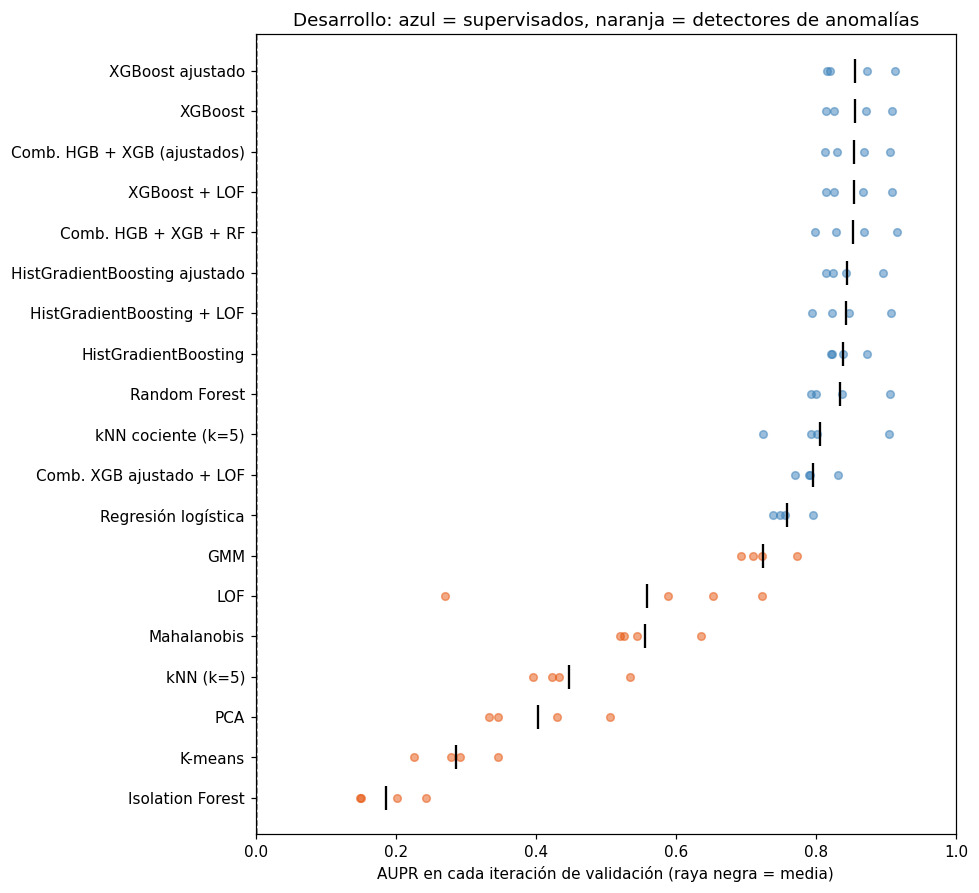

Modelo elegido: XGBoost ajustado  (AUPR medio 0.8557 ± 0.0464)


In [22]:
comparacion = resumen_cv(list(RESULTADOS))
display(comparacion)

fig, ax = plt.subplots(figsize=(9, 0.38 * len(comparacion) + 1))
for i, nombre in enumerate(comparacion.index[::-1]):
    aps = RESULTADOS[nombre]["folds"]["AUPR"]
    color = "#e6550d" if nombre in DETECTORES else "#377eb8"
    ax.scatter(aps, [i] * len(aps), color=color, alpha=0.5, s=25)
    ax.scatter(aps.mean(), i, color="black", marker="|", s=250)
ax.set_yticks(range(len(comparacion)), comparacion.index[::-1])
ax.axvline(PREVALENCIA, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("AUPR en cada iteración de validación (raya negra = media)")
ax.set_title("Desarrollo: azul = supervisados, naranja = detectores de anomalías")
ax.set_xlim(0, 1)
fig.tight_layout()
plt.show()

ELEGIDO = comparacion.index[0]
print(f"Modelo elegido: {ELEGIDO}  (AUPR medio {comparacion.loc[ELEGIDO, 'AUPR medio']:.4f} "
      f"± {comparacion.loc[ELEGIDO, 'AUPR desv.']:.4f})")

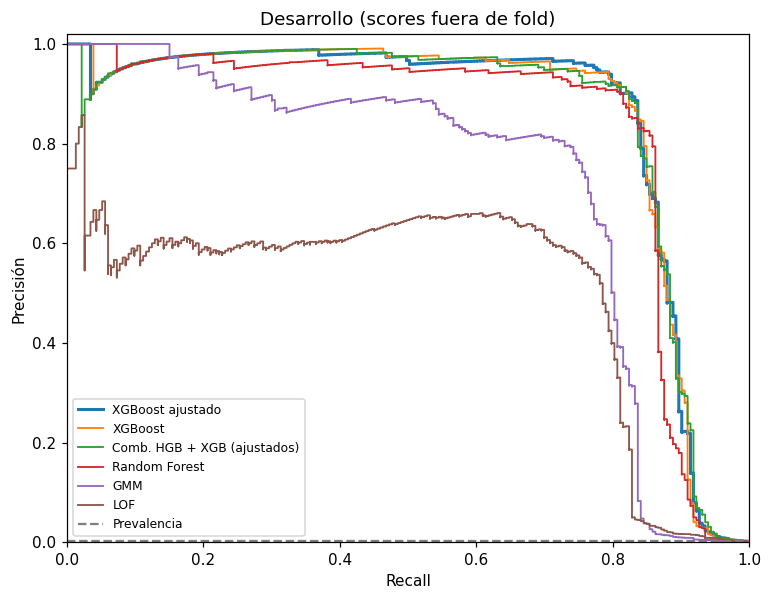

In [23]:
# Curvas precisión-recall con los scores fuera de fold de todo desarrollo (solo para visualizar).
fig, ax = plt.subplots(figsize=(8, 6))
for nombre in dict.fromkeys(list(comparacion.index[:3]) + ["Random Forest", "GMM", "LOF"]):
    oof = RESULTADOS[nombre]["oof"]
    # Rangos por iteración, para que las escalas de cada iteración sean comparables al juntar folds.
    rango = np.empty_like(oof)
    for k in FOLDS_CV:
        m = fold_dev == k
        rango[m] = rankdata(oof[m]) / m.sum()
    p, r, _ = precision_recall_curve(y_dev, rango)
    ax.step(r, p, where="post", label=nombre, linewidth=2 if nombre == ELEGIDO else 1.2)
ax.axhline(PREVALENCIA, color="gray", linestyle="--", label="Prevalencia")
ax.set(xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02),
       title="Desarrollo (scores fuera de fold)")
ax.legend(loc="lower left", fontsize=8)
plt.show()

**Lectura.**

- Por la regla fijada, el modelo elegido es **XGBoost ajustado** (AUPR 0,856 ± 0,046).
- Los cinco primeros (XGBoost con y sin ajuste, con LOF y las dos combinaciones) están a menos de 0,003 de
  AUPR entre sí: son **prácticamente equivalentes**, y cualquiera habría sido una elección razonable. El
  gráfico de puntos muestra que la variación entre iteraciones (0,82–0,91 para el elegido) es mucho mayor
  que la diferencia entre ellos.
- La separación clara está **entre familias**: árboles supervisados (≈0,83–0,86) > kNN supervisado y
  regresión logística (0,76–0,81) > GMM (0,73) > resto de detectores de anomalías.
- En las curvas precisión-recall, los modelos supervisados mantienen una precisión superior a 0,9
  hasta un recall de ≈0,8. GMM se mueve entre 0,8 y 0,9 y cae antes, y LOF apenas supera 0,6 en casi
  toda la curva.
- Todas las curvas se desploman a partir de un recall de ≈0,85–0,9: hay alrededor de un 10 % de fraudes
  que ningún modelo consigue distinguir de las transacciones normales.

# 9. Evaluación única en prueba

Ahora, y solo ahora, usamos prueba. El modelo elegido se entrena con **todo desarrollo** (folds 1–4) y
puntúa prueba (fold 0), que no ha intervenido en exploración, comparación, búsqueda de hiperparámetros
ni elección. Mostramos también LOF entrenado igual, como referencia de detección de anomalías; su
resultado no cambia la elección, que ya está cerrada.

Comprobado: ninguna de las 34,166 filas de prueba se ha usado antes de esta celda.


,AUPR,ROC AUC,Fraudes top-100,Fraudes en validación,AUPR trapezoidal,AUPR medio en desarrollo
Modelo,,,,,,
XGBoost ajustado,0.8243,0.9527,51,62,0.8241,0.8557
LOF (referencia),0.6223,0.9450,49,62,0.6172,0.5590


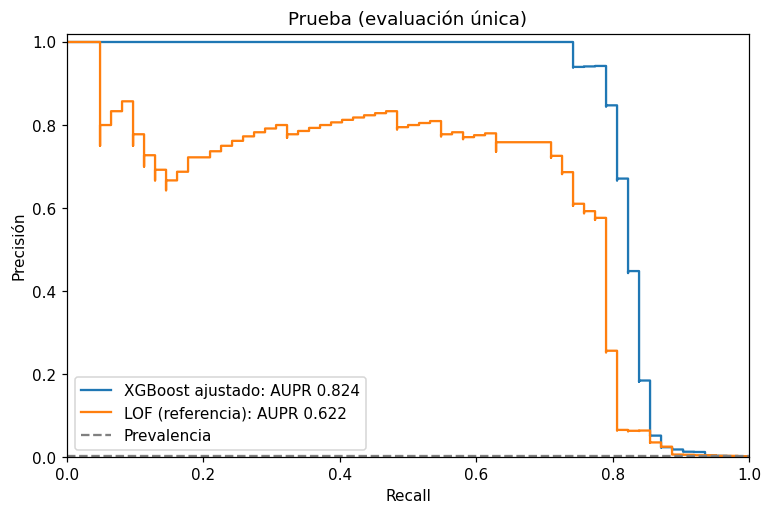

In [24]:
assert FILAS_USADAS_EN_DESARROLLO.isdisjoint(fila_prueba), "Prueba se ha usado durante el desarrollo"
print(f"Comprobado: ninguna de las {len(fila_prueba):,} filas de prueba se ha usado antes de esta celda.")

modelo_dev = CANDIDATOS[ELEGIDO]().fit(X_dev, y_dev)
scores_prueba = modelo_dev.score(X_prueba)
lof_dev = CANDIDATOS["LOF"]().fit(X_dev, y_dev)
scores_prueba_lof = lof_dev.score(X_prueba)

tabla_prueba = pd.DataFrame([
    {"Modelo": ELEGIDO, **metricas(y_prueba, scores_prueba)},
    {"Modelo": "LOF (referencia)", **metricas(y_prueba, scores_prueba_lof)},
]).set_index("Modelo")
tabla_prueba["AUPR trapezoidal"] = [auc(*precision_recall_curve(y_prueba, s)[1::-1])
                                    for s in (scores_prueba, scores_prueba_lof)]
tabla_prueba["AUPR medio en desarrollo"] = [comparacion.loc[ELEGIDO, "AUPR medio"], comparacion.loc["LOF", "AUPR medio"]]
display(tabla_prueba)

fig, ax = plt.subplots(figsize=(8, 5))
for nombre, s in [(ELEGIDO, scores_prueba), ("LOF (referencia)", scores_prueba_lof)]:
    p, r, _ = precision_recall_curve(y_prueba, s)
    ax.step(r, p, where="post", label=f"{nombre}: AUPR {average_precision_score(y_prueba, s):.3f}")
ax.axhline(y_prueba.mean(), color="gray", linestyle="--", label="Prevalencia")
ax.set(xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02), title="Prueba (evaluación única)")
ax.legend()
plt.show()

**Lectura.**

- En prueba, XGBoost ajustado obtiene **AUPR = 0,824**, frente a 0,622 de LOF.
- Es algo menos que la media de desarrollo (0,856), pero queda dentro del rango observado entre
  iteraciones (0,82–0,91). La diferencia se explica por el sesgo optimista de elegir el mejor de muchos
  candidatos y por el azar de qué 62 fraudes caen en prueba.
- Entre las 100 transacciones con mayor score hay 51 de los 62 fraudes de prueba: un recall del 82 % con
  una precisión del 51 % para ese presupuesto de revisión. LOF encuentra 49 en sus 100 primeras, pero
  intercala más normales por delante de los fraudes, y por eso su AUPR es menor.
- El AUPR calculado por integración trapezoidal es prácticamente igual (0,8241 frente a 0,8243): las dos
  formas de medir el área bajo la curva precisión-recall dan el mismo resultado.
- Esta es nuestra estimación honesta del rendimiento esperado en producción: **AUPR en torno a 0,82–0,85**.

# 10. Modelo final y scores de producción

Con la elección cerrada y evaluada, reentrenamos el mismo procedimiento con **toda la construcción**
(desarrollo + prueba): más fraudes etiquetados mejoran el modelo, y prueba ya ha cumplido su función.
Producción solo se usa para puntuar. El CSV tiene una única columna (`score`), una fila por transacción
de producción y el mismo orden que el fichero original; un valor mayor indica mayor sospecha de fraude.

In [25]:
X_const = df_const[columnas]
y_const = df_const["Class"].astype(int).to_numpy()
modelo_final = CANDIDATOS[ELEGIDO]().fit(X_const, y_const)
scores_produccion = np.asarray(modelo_final.score(X_prod), dtype=float)

# Comprobaciones antes de guardar
assert scores_produccion.shape == (N_PROD,), "Debe haber un score por fila de producción"
assert np.isfinite(scores_produccion).all(), "Hay scores no finitos"
assert pd.util.hash_pandas_object(X_prod, index=True).sum() == HUELLA_PROD, "Producción ha cambiado"
assert X_prod.index.equals(pd.RangeIndex(N_PROD)), "Producción ha cambiado de orden"
assert df_prod["Class"].isna().all(), "Producción no debe tener etiquetas"

RUTA_CSV = Path("entregable_scores_produccion.csv")
pd.DataFrame({"score": scores_produccion}).to_csv(RUTA_CSV, index=False)

# Releer el fichero y verificar que es exactamente lo que se pide
leido = pd.read_csv(RUTA_CSV)
assert leido.shape == (N_PROD, 1) and list(leido.columns) == ["score"]
assert np.allclose(leido["score"].to_numpy(), scores_produccion, rtol=1e-12, atol=0)
print(f"Guardado {RUTA_CSV.resolve()}: {leido.shape[0]:,} filas × {leido.shape[1]} columna.")
display(leido.describe().T)

n_esperados = round(PREVALENCIA * N_PROD)
print(f"Con la prevalencia de construcción se esperan ≈{n_esperados} fraudes en producción.")
print(f"Transacciones de producción con score > 0,5: {(scores_produccion > 0.5).sum()}")

Guardado C:\Users\1jose\Desktop\educacion\master_bme\modulo 5\anomalias\entregable_scores_produccion.csv: 113,923 filas × 1 columna.


,count,mean,std,min,25%,50%,75%,max
score,"113,923.0000",0.0016,0.0370,0.0000,0.0000,0.0000,0.0000,0.9994


Con la prevalencia de construcción se esperan ≈197 fraudes en producción.
Transacciones de producción con score > 0,5: 164


**Lectura.** Los scores son las probabilidades que estima XGBoost. Casi todas las transacciones reciben
valores muy cercanos a 0 y unas pocas valores altos, como corresponde a un 0,17 % de fraude. Para el AUPR
solo importa el orden, no que las probabilidades estén calibradas.

## 10.1. Diagnóstico: ¿se parece producción a construcción?

Si producción viniera de otra época o de otra población, el AUPR estimado podría no trasladarse. Lo
comprobamos con una **validación adversaria**: un clasificador intenta distinguir filas de construcción y
de producción usando solo las 21 entradas. Un ROC AUC cercano a 0,5 significa que no puede distinguirlas.
Este diagnóstico se ejecuta después de guardar el CSV y no modifica el modelo ni los scores.

In [26]:
entradas = pd.concat([X_const, X_prod], ignore_index=True)
origen = np.r_[np.zeros(len(X_const)), np.ones(N_PROD)]
p_origen = cross_val_predict(HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA),
                             entradas, origen, method="predict_proba",
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA))[:, 1]
print(f"ROC AUC adversaria construcción vs producción: {roc_auc_score(origen, p_origen):.4f}")
assert pd.read_csv(RUTA_CSV).shape == (N_PROD, 1)   # el entregable no ha cambiado

ROC AUC adversaria construcción vs producción: 0.4985


**Lectura.** Un ROC AUC ≈ 0,50 significa que el clasificador no distingue construcción de producción:
ambas parecen venir de la misma distribución. Es una buena noticia para la entrega, porque la estimación
obtenida en prueba debería trasladarse a producción.

# 11. Resumen de comprobaciones de separación

Reunimos en una celda las garantías de que entrenamiento, validación, prueba y producción se han
mantenido separados. Si alguna fallara, la celda daría error.

In [27]:
comprobaciones = {
    "Ningún grupo de transacciones idénticas cruza folds":
        asignacion.groupby("grupo")["fold"].nunique().eq(1).all(),
    "Desarrollo y prueba no comparten filas ni grupos":
        set(fila_dev).isdisjoint(fila_prueba) and grupos_dev.isdisjoint(asignacion.loc[es_prueba, "grupo"]),
    "En cada iteración, entrenamiento y validación son disjuntos y salen solo de desarrollo":
        all(set(fila_dev[i_tr]).isdisjoint(fila_dev[i_va]) and len(i_tr) + len(i_va) == len(fila_dev)
            for _, i_tr, i_va in iteraciones_cv()),
    "Ninguna fila de prueba entró en exploración, comparación, búsqueda o elección":
        FILAS_USADAS_EN_DESARROLLO.isdisjoint(fila_prueba),
    "Producción conserva contenido, orden y número de filas":
        pd.util.hash_pandas_object(X_prod, index=True).sum() == HUELLA_PROD and len(X_prod) == N_PROD,
    "Producción no tiene etiquetas y no se usó para entrenar el modelo de fraude":
        df_prod["Class"].isna().all() and len(X_const) == len(df_const),
    "CSV con una sola columna y una fila por transacción de producción":
        pd.read_csv(RUTA_CSV).shape == (N_PROD, 1),
}
display(pd.Series(comprobaciones, name="Correcto").to_frame())
assert all(comprobaciones.values())

,Correcto
Ningún grupo de transacciones idénticas cruza folds,True
Desarrollo y prueba no comparten filas ni grupos,True
"En cada iteración, entrenamiento y validación son disjuntos y salen solo de desarrollo",True
"Ninguna fila de prueba entró en exploración, comparación, búsqueda o elección",True
"Producción conserva contenido, orden y número de filas",True
Producción no tiene etiquetas y no se usó para entrenar el modelo de fraude,True
CSV con una sola columna y una fila por transacción de producción,True


# 12. Reflexión final

**Qué ha funcionado.** El factor decisivo ha sido usar las etiquetas. Los detectores de anomalías
aprenden solo cómo es lo normal, y el mejor de ellos (GMM) se queda en un AUPR de ≈0,73. Los modelos
supervisados de árboles alcanzan ≈0,84–0,86 en validación cruzada, y el elegido, XGBoost, obtiene 0,824
en prueba. El fraude de este conjunto no es simplemente "lo raro": probablemente hay transacciones
normales poco frecuentes y fraudes en zonas relativamente densas, y un modelo que ve ejemplos de fraude
aprende esa diferencia. Coincide con la conclusión de ADBench vista en clase.

**Qué no ha funcionado, o ha aportado poco.**

- LOF como variable añadida no mejora a los árboles, y mezclarlo por media de rangos empeora el resultado.
- La búsqueda de hiperparámetros y las combinaciones de modelos dan mejoras de milésimas, indistinguibles
  del ruido.
- Con ≈60 fraudes por partición, la incertidumbre del AUPR (±0,04) es mayor que casi todas las
  diferencias entre buenos modelos. Elegir entre ellos es casi indiferente; lo importante es elegir bien
  la familia de modelos.
- Alrededor de un 10 % de los fraudes queda mal ordenado por todos los modelos: las curvas
  precisión-recall caen a partir de un recall de ≈0,85–0,9. Ese es el margen de mejora real, y parece
  difícil alcanzarlo solo con estas 21 variables.

**Lecciones sobre la evaluación.**

- **Una sola partición de validación engaña.** LOF va de 0,27 a 0,72 según la iteración. Por eso usamos
  validación cruzada en desarrollo y reservamos prueba para una única evaluación.
- **El ROC AUC no sirve para comparar con este desbalance.** La regresión logística tiene el mayor ROC AUC
  y un AUPR claramente menor; Isolation Forest, ROC AUC 0,965 y el peor AUPR.
- **Las transacciones idénticas deben ir juntas.** Si una copia queda en entrenamiento y otra en
  validación, las métricas se inflan.
- **La reproducibilidad no está garantizada solo con fijar la semilla.** El reparto de
  `StratifiedGroupKFold` cambiaba con la versión de scikit-learn; por eso hacemos el reparto a mano con un
  generador estable.

**Limitaciones.**

- No hay fecha ni identificador de tarjeta, así que no podemos asegurar independencia por cliente o por
  tiempo; la validación adversaria (ROC AUC ≈ 0,50) sugiere al menos que producción se parece a
  construcción.
- Las probabilidades no están calibradas; para el AUPR no importa, pero sí si se quisieran usar como
  probabilidad real de fraude.
- La búsqueda de hiperparámetros es limitada (20 configuraciones por modelo) y su resultado depende de
  pocos fraudes.

**Posibles mejoras.** Promediar varias semillas de XGBoost para reducir varianza, probar otros
modelos de *boosting* (CatBoost, LightGBM bien regularizado), hacer una búsqueda más amplia con
validación cruzada anidada y, si se dispusiera de variables temporales o de cliente, validar respetando
el tiempo y construir variables de comportamiento por tarjeta.